# CatDSGE for India: the disaster in the nonlinear model

The 10% capital destruction of `04_catdsge_india_disaster_example.ipynb`, solved in the nonlinear model under perfect foresight at every posterior draw of `03_catdsge_estimation.ipynb`, and compared against the first-order welfare cost and impulse responses.

In [1]:
import multiprocessing
import warnings

from concurrent.futures import ProcessPoolExecutor
from itertools import product
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pymc as pm
import xarray as xr

from tqdm.auto import tqdm

import gEconpy as ge

from catdsge import (build_observed,
                     build_pymc_model,
                     build_welfare_model,
                     calibrate_india,
                     configure_session,
                     fixed_parameters,
                     load_estimation_statespace,
                     load_simulation_statespace,
                     median_and_hdi,
                     plot_clipped_densities,
                     simulation_trace,
                     statespace_trace)
from climate_risk.dsge.model_files import GCN_DIR
from climate_risk.plotting import PALETTE

configure_session()
data_dir = Path("data")

In [2]:
model = ge.model_from_gcn(GCN_DIR / "catdsge_v4.gcn")
panel = pd.read_parquet(data_dir / "india_mixed_frequency.parquet")
panel.index = panel.index.to_period("Q")

india_parameters = calibrate_india(model, panel)
india_model_parameters = model.parameters(**india_parameters)

In [3]:
statespace = load_estimation_statespace()
estimated_shocks = list(statespace.shock_names)

observed = build_observed(panel)
fit_data = observed.set_axis(observed.index.to_timestamp())
pymc_model = build_pymc_model(statespace=statespace,
                              fit_data=fit_data,
                              model_parameters=india_model_parameters)

In [4]:
with xr.open_datatree(data_dir / "catdsge_flow_tight_shocks_idata.nc") as saved_trace:
    map_init_idata = saved_trace.load()
posterior_draws = map_init_idata.posterior.to_dataset()
solved = posterior_draws["deterministic_norm"] <= 1e-6

observed_data = xr.Dataset({"obs": (("time", "observed_state"), fit_data.to_numpy())},
                           coords={"time": fit_data.index.rename("time"),
                                   "observed_state": fit_data.columns})
statespace_idata = statespace_trace(draws=posterior_draws,
                                    parameter_values=fixed_parameters(statespace, india_model_parameters),
                                    observed_data=observed_data,
                                    group="posterior")

The first-order impulse responses and welfare cost of `04_catdsge_india_disaster_example.ipynb`, which the nonlinear solutions are compared against.

In [5]:
IRF_QUARTERS = 40

simulation_statespace = load_simulation_statespace()
analysis_idata = simulation_trace(simulation_statespace=simulation_statespace,
                                  estimated_shocks=estimated_shocks,
                                  draws=posterior_draws,
                                  model_parameters=india_model_parameters,
                                  observed_data=observed_data,
                                  group="posterior")

simulation_shocks = list(simulation_statespace.shock_names)
destruction_trajectory = np.zeros((IRF_QUARTERS, len(simulation_shocks)))
destruction_trajectory[0, simulation_shocks.index("epsilon_xi_K")] = -0.10
capital_destruction_irf = simulation_statespace.impulse_response_function(analysis_idata,
                                                                          shock_trajectory=destruction_trajectory,
                                                                          random_seed=20261014)["irf"]
welfare_costs = pm.compute_deterministics(posterior_draws,
                                          model=build_welfare_model(pymc_model, simulation_statespace),
                                          var_names=["welfare_cost"]).where(solved)

Sampling: []


Output()

Output()

## 1. Nonlinear welfare cost under perfect foresight

The disaster is solved in the nonlinear model under perfect foresight: households are surprised by the destruction in 2015Q1 and expect no further shocks. Lifetime utility $U$ and its consumption part $U_C = (C - \phi_H C_{-1})^{1-\sigma} / (1 - \sigma) + \beta \, \mathbb{E} \, U_{C,+1}$ are model variables, so their 2015Q1 values on the baseline and disaster paths give the consumption-equivalent variation exactly:

$$
(1 + \lambda)^{1 - \sigma} = \frac{U^{d} - U^{b} + U^{b}_C}{U^{b}_C}
$$

From the steady state the baseline is the steady state itself, so each draw needs one solve there and two from its smoothed 2014Q4 state. The gap between the two starting points is the state dependence the first-order cost cannot have, and the gap between either and the first-order cost is the nonlinearity. The shock is the same as in the first-order cost. Every posterior draw is solved, in parallel worker processes.

Draws on which Newton's method fails are left out of the comparison below, which uses only the draws every method solves. The solver's homotopy fallback is off. On this posterior it recovers almost none of the failed draws and multiplies the runtime.

In [6]:
# The Kalman filter samplers read the data from constant_data.
filter_idata = xr.DataTree.from_dict({"posterior": statespace_idata["posterior"].to_dataset(),
                                      "observed_data": observed_data,
                                      "constant_data": xr.Dataset({"data": observed_data["obs"]})})
smoothed_states = statespace.sample_filter_outputs(filter_idata,
                                                   filter_output_names="smoothed_states",
                                                   random_seed=20261014)["posterior_predictive"]["smoothed_states"]

Sampling: []


Output()

In [7]:
PERFECT_FORESIGHT_QUARTERS = 400
WELFARE_WORKERS = 10
ESTIMATED_STRUCTURAL = ["phi_H", "chi", "psi_z", "gamma_I", "theta_H", "gamma_H", "phi_pi", "phi_y", "rho_i",
                        "phi_debt", "theta_w"]

disaster_shocks = {"epsilon_xi_K": np.r_[-0.10, np.zeros(PERFECT_FORESIGHT_QUARTERS - 1)]}
posterior_draw_shape = (posterior_draws.sizes["chain"], posterior_draws.sizes["draw"])
chain_draw_pairs = list(product(posterior_draws["chain"].values, posterior_draws["draw"].values))

# The estimation model also smooths measurement-noise states, which the simulation model does not have.
simulation_variables = {variable.base_name for variable in model.variables}
smoothed_start_levels = statespace.deviations_to_levels(smoothed_states.sel(time=pd.Timestamp("2014-10-01")),
                                                        statespace_idata)
smoothed_start_levels = smoothed_start_levels.sel(state=[state for state in smoothed_start_levels["state"].values
                                                         if state in simulation_variables])


def parameters_and_steady_state(chain, draw):
    parameters = {**india_parameters,
                  **{name: float(posterior_draws[name].sel(chain=chain, draw=draw)) for name in ESTIMATED_STRUCTURAL}}
    steady_state = model.steady_state(verbose=False,
                                      progressbar=False,
                                      **parameters)
    return parameters, steady_state


def solve_path(parameters, steady_state, initial_conditions=None, shocks=None):
    """The perfect-foresight path in levels, or None when the solver fails."""
    trajectory, result = ge.solve_perfect_foresight(model,
                                                    simulation_length=PERFECT_FORESIGHT_QUARTERS,
                                                    x0=dict(steady_state),
                                                    initial_conditions=initial_conditions,
                                                    shocks=shocks,
                                                    steady_state_kwargs=parameters,
                                                    sparse_root_kwargs={"progressbar": False},
                                                    max_homotopy_solves=0)
    return trajectory if result.success else None


def lifetime_utility_in_2015q1(parameters, steady_state, initial_conditions=None, shocks=None):
    """Lifetime utility and its consumption part in the first quarter of the perfect-foresight path."""
    trajectory = solve_path(parameters=parameters,
                            steady_state=steady_state,
                            initial_conditions=initial_conditions,
                            shocks=shocks)
    if trajectory is None:
        return np.nan, np.nan
    return trajectory["U"].iloc[0], trajectory["U_C"].iloc[0]


def consumption_equivalent(baseline, disaster, risk_aversion):
    (baseline_utility, baseline_consumption_utility), (disaster_utility, _) = baseline, disaster
    ratio = (disaster_utility - baseline_utility + baseline_consumption_utility) / baseline_consumption_utility
    return ratio ** (1 / (1 - risk_aversion)) - 1


def map_over_posterior_draws(function):
    """Apply `function` to every (chain, draw) pair in worker processes forked from this kernel."""
    with warnings.catch_warnings():
        # The workers run only the compiled model residuals and scipy, never JAX, so forking after JAX has started
        # its threads is safe here.
        warnings.filterwarnings("ignore", message=r"os\.fork\(\) was called")
        with ProcessPoolExecutor(max_workers=WELFARE_WORKERS,
                                 mp_context=multiprocessing.get_context("fork")) as pool:
            try:
                return list(tqdm(pool.map(function, chain_draw_pairs),
                                 total=len(chain_draw_pairs),
                                 desc="posterior draws"))
            except KeyboardInterrupt:
                # Queued draws are dropped so an interrupt waits only for the draws already running.
                pool.shutdown(wait=False, cancel_futures=True)
                raise

In [8]:
risk_aversion = float(india_model_parameters["sigma"])


def nonlinear_welfare_costs_for_draw(chain_draw):
    """Consumption-equivalent cost of the disaster for one draw, from the steady state and from 2014Q4."""
    chain, draw = chain_draw
    parameters, steady_state = parameters_and_steady_state(chain=chain, draw=draw)
    start = smoothed_start_levels.sel(chain=chain, draw=draw).reset_coords(drop=True)

    disaster_from_steady_state = lifetime_utility_in_2015q1(parameters=parameters,
                                                            steady_state=steady_state,
                                                            shocks=disaster_shocks)
    baseline_from_start = lifetime_utility_in_2015q1(parameters=parameters,
                                                     steady_state=steady_state,
                                                     initial_conditions=start)
    disaster_from_start = lifetime_utility_in_2015q1(parameters=parameters,
                                                     steady_state=steady_state,
                                                     initial_conditions=start,
                                                     shocks=disaster_shocks)
    return (consumption_equivalent(baseline=(steady_state["U_ss"], steady_state["U_C_ss"]),
                                   disaster=disaster_from_steady_state,
                                   risk_aversion=risk_aversion),
            consumption_equivalent(baseline=baseline_from_start,
                                   disaster=disaster_from_start,
                                   risk_aversion=risk_aversion))


costs = map_over_posterior_draws(nonlinear_welfare_costs_for_draw)
nonlinear_welfare_costs = xr.Dataset({name: (("chain", "draw"), np.reshape([cost[column] for cost in costs],
                                                                           posterior_draw_shape))
                                      for column, name in enumerate(["from the steady state", "from 2014Q4"])},
                                     coords={"chain": posterior_draws["chain"], "draw": posterior_draws["draw"]})
nonlinear_welfare_costs = nonlinear_welfare_costs.where(solved)

posterior draws:   0%|          | 0/2000 [00:00<?, ?it/s]

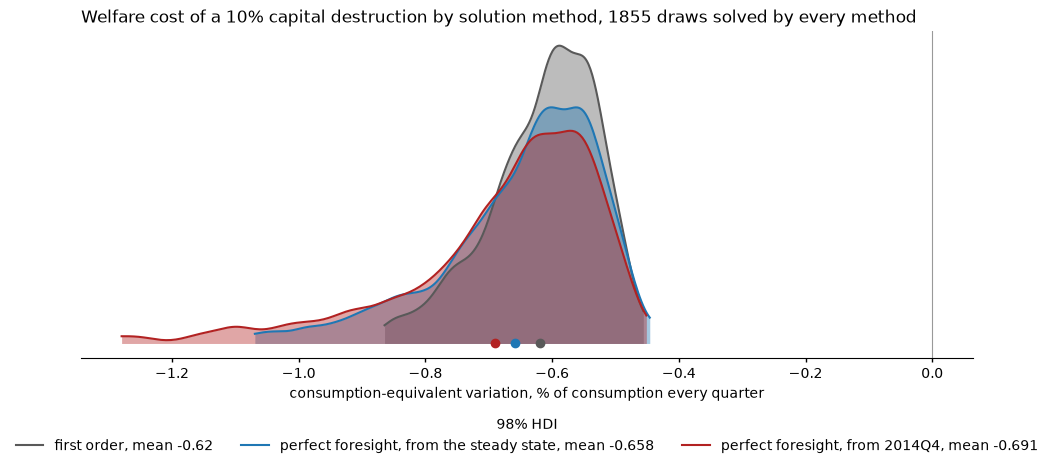

In [9]:
DESTRUCTION_COLOR = "firebrick"

welfare_cost_comparison = 100 * xr.Dataset({"first order": welfare_costs["welfare_cost"],
                                           **{f"perfect foresight, {name}": cost
                                              for name, cost in nonlinear_welfare_costs.items()}})
comparison_samples = (welfare_cost_comparison.stack(sample=("chain", "draw"))
                      .dropna("sample")
                      .drop_vars(["sample", "chain", "draw"]))

plot_clipped_densities(samples=comparison_samples,
                       colors=["0.35", PALETTE["primary"], DESTRUCTION_COLOR],
                       xlabel="consumption-equivalent variation, % of consumption every quarter",
                       title=f"Welfare cost of a 10% capital destruction by solution method, "
                             f"{comparison_samples.sizes['sample']} draws solved by every method",
                       mean_labels="legend");

## 2. Perfect-foresight paths against first order

The disaster from the steady state, so the first-order paths are the posterior impulse responses of `04_catdsge_india_disaster_example.ipynb`, on the same draws. Draws the perfect-foresight solver fails on are dropped from both.

In [10]:
DESTRUCTION_VARIABLES = {"GDP": "GDP (%)",
                         "C": "consumption (%)",
                         "I": "investment (%)",
                         "K": "capital stock (%)",
                         "L": "hours (%)",
                         "z": "utilization (%)",
                         "X": "exports (%)",
                         "M": "imports (%)"}


def disaster_response_from_steady_state(chain_draw):
    """Percent deviations from steady state of the disaster's perfect-foresight path for one draw."""
    chain, draw = chain_draw
    parameters, steady_state = parameters_and_steady_state(chain=chain, draw=draw)
    trajectory = solve_path(parameters=parameters,
                            steady_state=steady_state,
                            shocks=disaster_shocks)
    if trajectory is None:
        return np.full((IRF_QUARTERS, len(DESTRUCTION_VARIABLES)), np.nan)
    levels = trajectory[list(DESTRUCTION_VARIABLES)].iloc[:IRF_QUARTERS].to_numpy()
    steady_levels = np.array([steady_state[f"{name}_ss"] for name in DESTRUCTION_VARIABLES])
    return 100 * np.log(levels / steady_levels)


responses = map_over_posterior_draws(disaster_response_from_steady_state)
perfect_foresight_response = xr.DataArray(np.reshape(responses, (*posterior_draw_shape, IRF_QUARTERS, -1)),
                                          dims=["chain", "draw", "time", "variable"],
                                          coords={"chain": posterior_draws["chain"],
                                                  "draw": posterior_draws["draw"],
                                                  "variable": list(DESTRUCTION_VARIABLES)})
perfect_foresight_solved = perfect_foresight_response.notnull().all(["time", "variable"])
first_order_response = (100 * capital_destruction_irf.sel(state=list(DESTRUCTION_VARIABLES))
                        .rename(state="variable")
                        .drop_vars("time"))

posterior draws:   0%|          | 0/2000 [00:00<?, ?it/s]

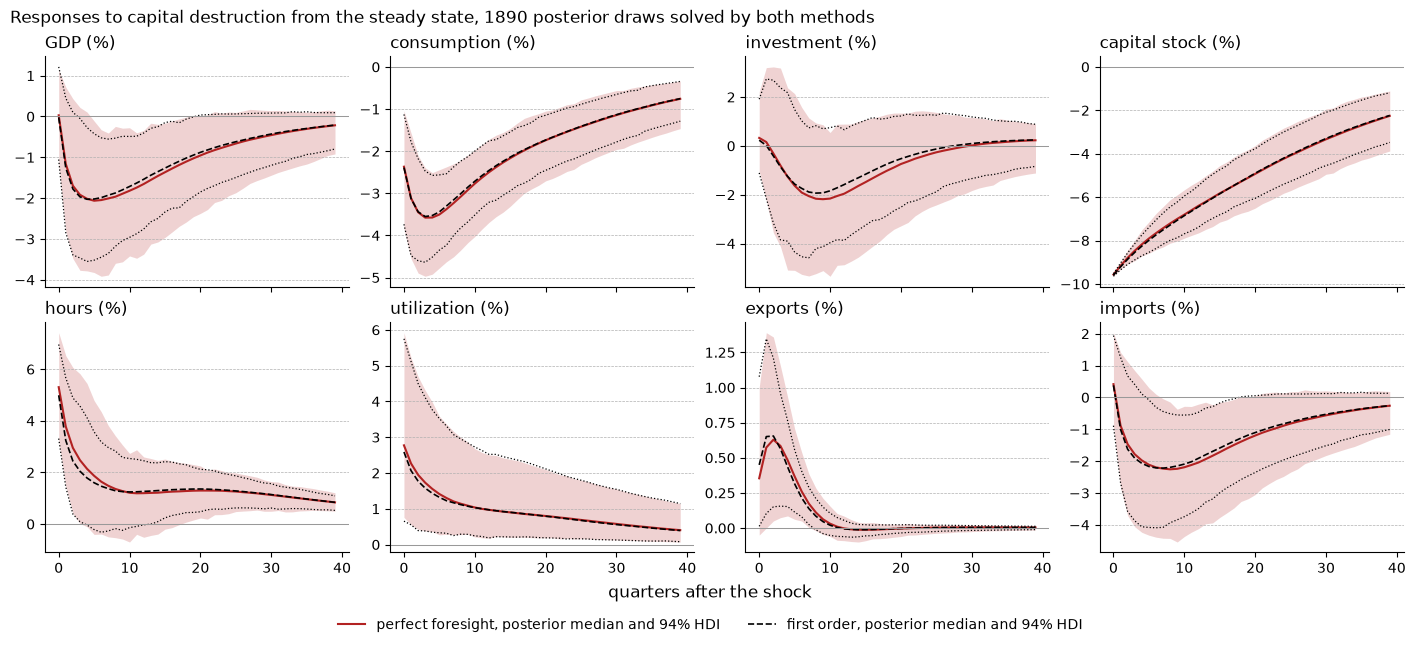

In [11]:
comparison_mask = perfect_foresight_solved & solved
quarters = np.arange(IRF_QUARTERS)

fig, axes = plt.subplots(nrows=2,
                         ncols=4,
                         figsize=(14, 6),
                         sharex=True,
                         layout="constrained")
for ax, (variable, label) in zip(axes.ravel(), DESTRUCTION_VARIABLES.items(), strict=True):
    nonlinear_median, nonlinear_interval = median_and_hdi(perfect_foresight_response.sel(variable=variable)
                                                          .where(comparison_mask))
    linear_median, linear_interval = median_and_hdi(first_order_response.sel(variable=variable)
                                                    .where(comparison_mask))
    ax.fill_between(quarters,
                    nonlinear_interval.sel(ci_bound="lower"),
                    nonlinear_interval.sel(ci_bound="upper"),
                    color=DESTRUCTION_COLOR,
                    alpha=0.2,
                    linewidth=0)
    ax.plot(quarters,
            nonlinear_median,
            color=DESTRUCTION_COLOR,
            lw=1.5,
            label="perfect foresight, posterior median and 94% HDI")
    ax.plot(quarters,
            linear_median,
            color="k",
            ls="--",
            lw=1.2,
            label="first order, posterior median and 94% HDI")
    for bound in ["lower", "upper"]:
        ax.plot(quarters,
                linear_interval.sel(ci_bound=bound),
                color="k",
                ls=":",
                lw=0.9)
    ax.axhline(0.0, color="0.6", lw=0.75)
    ax.set_title(label, loc="left")

handles, labels = axes.flat[0].get_legend_handles_labels()
fig.legend(handles=handles,
           labels=labels,
           loc="upper center",
           bbox_to_anchor=(0.5, 0.0),
           ncol=len(labels),
           frameon=False)
fig.supxlabel("quarters after the shock")
fig.suptitle(f"Responses to capital destruction from the steady state, {int(comparison_mask.sum())} posterior draws "
             "solved by both methods",
             x=0.0,
             ha="left");